# Complex analysis 1: Complex functions and how to picture them

*Learning path: complex analysis, part 1 of 8.* [Index](README.md) · Previous: [Held, simplify, eval](00-held-simplify-eval.ipynb) · Next: [Analytic functions](02-analytic-functions.ipynb)

A real function $y = f(x)$ is a curve in the plane. A complex function $w = f(z)$ takes a point of one plane to a point of
another, so its graph would need four dimensions. How do you look at something you cannot draw? This lesson gives two
answers. One draws what $f$ does to a grid: lines go in, curves come out. The other paints every point $z$ with a color
that encodes $f(z)$, so that zeros and poles show up as places where all the colors meet. With these two pictures, the
rest of the path (derivatives, integrals, residues) will be things you can see.

**Who this is for.** You know complex numbers: $a + bi$, the modulus and argument, and Euler's formula
$e^{i\theta} = \cos\theta + i\sin\theta$ ([foundations 6](../foundations/06-complex-numbers.ipynb) reviews them). You
have met functions of two variables ([multivariable calculus 1](../multivariable/01-functions-of-two-variables.ipynb)).

**What you will be able to do afterwards:**

1. compute with complex numbers in Cartesian and polar form, and use $e^{x + iy} = e^x(\cos y + i \sin y)$;
2. split a complex function into its real and imaginary parts $u(x, y)$ and $v(x, y)$;
3. draw the image of a grid under a map with `cmap`, and describe $z^2$, $1/z$ and $e^z$ as maps;
4. read a domain coloring made with `cplot`: find zeros and poles and their orders.

Plan about an hour.

## 1. Complex numbers, quickly

A complex number $z = x + iy$ is a point $(x, y)$ of the plane. In polar form $z = r e^{i\theta}$, with modulus
$r = |z|$ and argument $\theta$. Multiplying multiplies the moduli and adds the arguments, which is why powers are easy
in polar form. Galileo writes $i$ as `i`:

In [1]:
w = 1 + i*sqrt(3);
simplify(abs(w))
arg(w)
polar(w)
expand(w^3)

2

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

pi/3

> `arg` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

[2, pi/3]

> `polar` (see `rect`): rect writes z as a + b*i; polar gives [r, phi] with z = r*exp(i*phi).

-8

> `expand`: Multiplies out products and powers.

$|w| = 2$ and $\arg w = \pi/3$, so $w^3$ has modulus 8 and argument $\pi$: it is $-8$. The equation $z^3 = 1$ has
three solutions, spaced by a third of a turn on the unit circle:

In [2]:
solve(u^3 - 1, u)

[1, (-1-sqrt(3)*i)/2, (-1+sqrt(3)*i)/2]

> Rational roots (rational root test): 1; what is left is `u^2+u+1` = 0.
>
> **Quadratic formula** u = (−b ± sqrt(D))/(2a) with D = b^2 − 4ac = `-3`; D < 0: two complex roots.

**Try this.** Compute $(1 + i)^8$ by hand in polar form, then check with `expand((1 + i)^8)`.

## 2. Real and imaginary parts

Write $z = x + iy$ with $x, y$ real. Then any complex function splits as $f(z) = u(x, y) + i\,v(x, y)$. For $z^2$:

$$ (x + iy)^2 = x^2 - y^2 + 2ixy, \qquad u = x^2 - y^2, \quad v = 2xy.$$

`real` and `imag` do this, treating $x$ and $y$ as real:

In [3]:
real((x + i*y)^2)
imag((x + i*y)^2)
real(1/(x + i*y))
imag(1/(x + i*y))

x^2-y^2

> `real`: Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

2*x*y

> `imag` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

x/(x^2+y^2)

> `real`: Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

-y/(x^2+y^2)

> `imag` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

For the exponential, Euler's formula gives $e^{x + iy} = e^x e^{iy} = e^x(\cos y + i \sin y)$:

In [4]:
real(exp(x + i*y))
imag(exp(x + i*y))
simplify(abs(exp(x + i*y)))

exp(x)*cos(y)

> `real`: Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

exp(x)*sin(y)

> `imag` (see `real`): Real part, imaginary part, complex conjugate, modulus |z| and argument (angle) of z.

exp(x)

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

So $|e^z| = e^x$ depends only on the real part, and the imaginary part $y$ is an angle: $e^z$ is periodic with period
$2\pi i$. And $e^z$ is never 0, since $e^x > 0$.

**Try this.** Find the real and imaginary parts of $\sin(x + iy)$. Is $\sin z$ bounded in the complex plane, as it is on
the real line?

## 3. Pictures of maps: what happens to a grid

`cmap(f, z, x0, x1, y0, y1)` draws the images under $f$ of the horizontal lines (blue) and vertical lines (red) of a
grid on the rectangle $x_0 \le \operatorname{Re} z \le x_1$, $y_0 \le \operatorname{Im} z \le y_1$. Squaring doubles
arguments, so the quarter plane opens into a half plane, and the grid lines become parabolas:

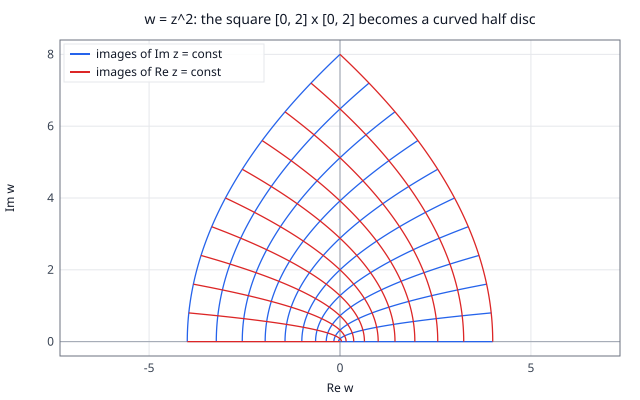

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [5]:
p = cmap(z^2, z, 0, 2, 0, 2);
labels(title(p, "w = z^2: the square [0, 2] x [0, 2] becomes a curved half disc"), "Re w", "Im w")

The exponential turns vertical lines $x = c$ into circles of radius $e^c$ and horizontal lines $y = c$ into rays at
angle $c$: Cartesian coordinates become polar coordinates.

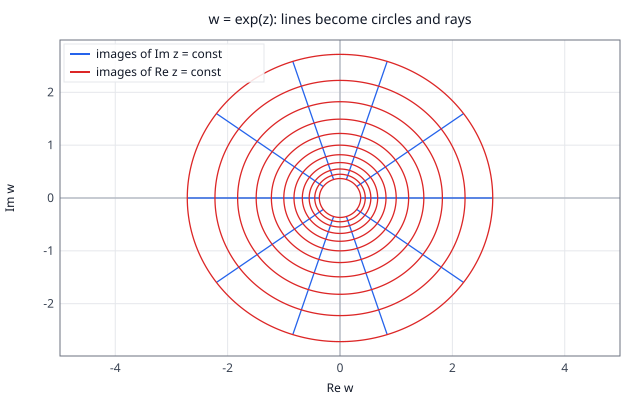

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [6]:
p = cmap(exp(z), z, -1, 1, -pi, pi);
labels(title(p, "w = exp(z): lines become circles and rays"), "Re w", "Im w")

Notice in both pictures that the images of the two families of lines still cross at right angles. That is no
accident: it is the property of **conformal** maps, the subject of [lesson 8](08-conformal-maps.ipynb).

**Try this.** Draw `cmap(1/z, z, 0.5, 2, 0.5, 2)`. What do the lines become? (Hint: lesson 8 shows that $1/z$ maps
lines and circles to lines and circles.)

## 4. Domain coloring

The second picture paints each point $z$ by the value $f(z)$: the **hue** shows the argument of $f(z)$ (red for
positive reals, then yellow, green, cyan, blue and magenta as the argument goes round), and the **brightness** shows the
modulus (dark for small, light for large). Start with $f(z) = z$ itself, the color wheel:

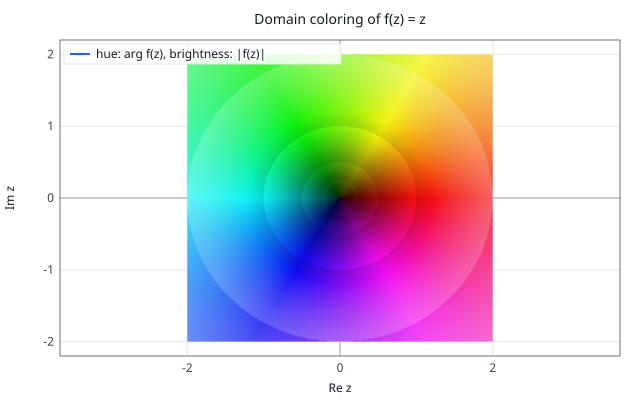

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
p = cplot(z, z, -2, 2, -2, 2);
labels(title(p, "Domain coloring of f(z) = z"), "Re z", "Im z")

Red along the positive real axis, cyan along the negative one, black at the zero, and the colors go once round it
counterclockwise. For $z^2$ they go round **twice**, because squaring doubles the argument:

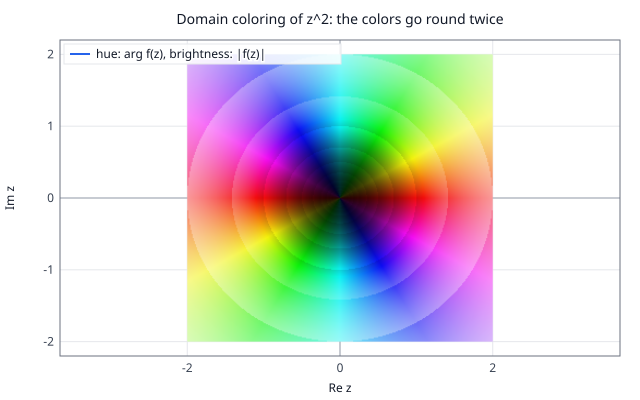

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
p = cplot(z^2, z, -2, 2, -2, 2);
labels(title(p, "Domain coloring of z^2: the colors go round twice"), "Re z", "Im z")

Now a function with zeros at $\pm 1$ and poles at $\pm i$:

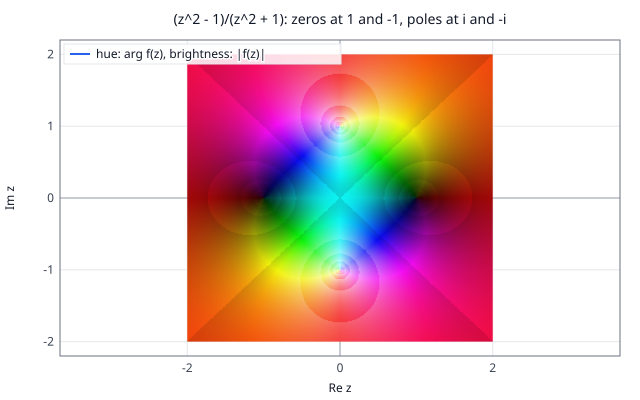

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [9]:
p = cplot((z^2 - 1)/(z^2 + 1), z, -2, 2, -2, 2);
labels(title(p, "(z^2 - 1)/(z^2 + 1): zeros at 1 and -1, poles at i and -i"), "Re z", "Im z")

At a **zero** the colors meet in a dark point and go round counterclockwise; at a **pole** they meet in a white point
and go round **clockwise** (the argument of $1/z$ turns backwards). The number of times the colors go round is the
order of the zero or pole. The faint curves are places where $|f|$ is a power of 2; the two diagonals are where
$|f| = 1$.

**Try this.** Make a function with a double zero at $0$ and a simple pole at $1$, and check the picture:
`cplot(z^2/(z - 1), z, -2, 2, -2, 2)`.

## 5. The exponential and the logarithm

Domain coloring shows the periodicity of $e^z$: the picture repeats every $2\pi$ vertically, and the brightness depends
only on $\operatorname{Re} z$.

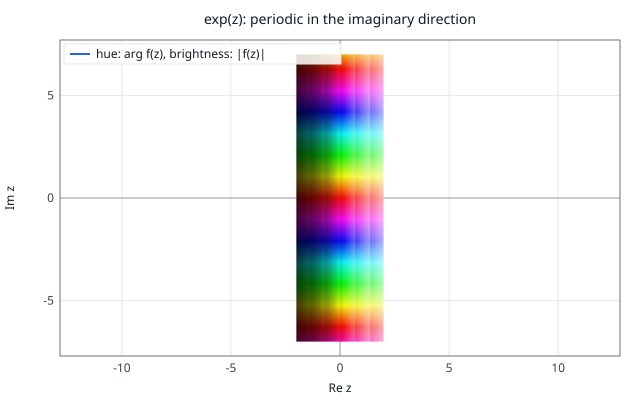

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
p = cplot(exp(z), z, -2, 2, -7, 7);
labels(title(p, "exp(z): periodic in the imaginary direction"), "Re z", "Im z")

Because $e^z$ takes each value infinitely often ($e^{z + 2\pi i k} = e^z$), the **logarithm** has infinitely many values:
$\log w = \ln|w| + i(\arg w + 2\pi k)$. Choosing $-\pi < \arg w \le \pi$ gives the **principal** logarithm, which jumps
by $2\pi i$ across the negative real axis, its **branch cut**:

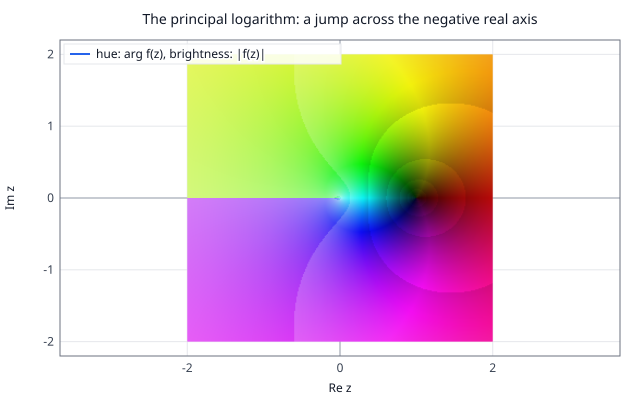

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [11]:
p = cplot(log(z), z, -2, 2, -2, 2);
labels(title(p, "The principal logarithm: a jump across the negative real axis"), "Re z", "Im z")

The colors change abruptly along the negative real axis. Square roots, $z^{1/2} = e^{(\log z)/2}$, inherit the cut.
Such **branch points** are a different kind of singularity from zeros and poles; [lesson 5](05-taylor-and-laurent.ipynb)
classifies the singularities.

**Try this.** Draw `cplot(sqrt(z), z, -2, 2, -2, 2)`. How many times do the colors go round the origin before the cut?

## Summary

* $z = x + iy = re^{i\theta}$; multiplication multiplies moduli and adds arguments.
* A complex function is a pair of real functions: $f = u + iv$, found with `real` and `imag`.
* $e^{x + iy} = e^x(\cos y + i\sin y)$: periodic with period $2\pi i$, never zero. The logarithm is many-valued; the
  principal branch has a cut along the negative real axis.
* `cmap` shows the images of grid lines; `cplot` colors $z$ by $f(z)$. Zeros are dark, poles are light, and the colors
  turn once per order, counterclockwise around zeros and clockwise around poles.

Next: [analytic functions](02-analytic-functions.ipynb), complex functions that have a derivative.

## Exercises

1. **Roots of unity.** Solve $z^6 = 1$ and plot the solutions in your head on the unit circle. What is their sum?
2. **Parts.** Find $u$ and $v$ for $f(z) = z^3$ and for $f(z) = \bar z = x - iy$.
3. **A grid under $z^3$.** Draw `cmap(z^3, z, 0, 1.5, 0, 1.5)`. What angle does the image of the quarter plane open to?
4. **Read the colors.** Predict the domain coloring of $(z - 1)^2/(z + 1)^3$, then draw it with `cplot`.
5. **Cosine.** Show that $\cos(iy) = \cosh y$, and use it to solve $\cos z = 2$. (Hint: try $z = iy$.)

## Hints and answers

* **Section 1, Try this.** $1 + i = \sqrt 2\,e^{i\pi/4}$, so $(1 + i)^8 = 16\,e^{2\pi i} = 16$.
* **Section 2, Try this.** $\sin(x + iy) = \sin x\cosh y + i\cos x\sinh y$. No: along the imaginary axis it grows like
  $e^{|y|}/2$.
* **Section 3, Try this.** Circles through the origin: the lines $x = c$ and $y = c$ become circles tangent to the axes.
* **Section 4, Try this.** The colors go twice counterclockwise around 0 and once clockwise around 1.
* **Section 5, Try this.** Half a turn: $\sqrt z$ halves the argument, so the colors only reach halfway before the cut.
* **Exercise 1.** $e^{2\pi i k/6}$, $k = 0, \ldots, 5$; their sum is 0.
* **Exercise 2.** $z^3$: $u = x^3 - 3xy^2$, $v = 3x^2y - y^3$. $\bar z$: $u = x$, $v = -y$.
* **Exercise 3.** Three right angles: $3\pi/2$, since $z^3$ triples arguments.
* **Exercise 4.** Colors twice counterclockwise around the zero at 1, three times clockwise around the pole at $-1$.
* **Exercise 5.** $\cos(iy) = (e^{-y} + e^{y})/2 = \cosh y$; $\cosh y = 2$ gives $y = \pm\log(2 + \sqrt 3)$, so
  $z = 2\pi k \pm i\log(2 + \sqrt 3)$.

## Sources

1. T. Needham, *Visual Complex Analysis*, Oxford University Press (1997), chapters 1 to 3.
2. E. Wegert, *Visual Complex Functions: An Introduction with Phase Portraits*, Birkhäuser (2012) (domain coloring).
3. J. W. Brown and R. V. Churchill, *Complex Variables and Applications*, 9th ed., McGraw-Hill (2014), chapters 1 to 3.